# Clustering Introduction - Nigerian Music

## Summary

In this notebook we explore a real dataset and try the main ideas from the *Clustering Introduction* slides ourselves.

**The data:** 530 Nigerian songs from Spotify. Each song has text information (name, album, artist, genre) and numbers that describe how it sounds (popularity, danceability, energy, loudness and more).

**Outline:**

| Section | What we do | Why |
|---|---|---|
| 0–1 | Set up and load the data | |
| 2 | Inspect the data | Find problems before they spoil our results |
| 3 | Clean the data | Remove rows we can't trust |
| 4 | Explore with plots | See which features are related and whether the genres look different |
| 5 | Measure distance | Clustering groups points that are *close*, so we need to measure "close" |
| 6 | Scale the features | Make every feature count equally |
| 7 | Hierarchical clustering | Build a tree of clusters and choose k afterwards |
| 8 | K-means vs DBSCAN | See that the shape of the data decides which algorithm works |
| 9 | *(Optional)* Soft clustering | Let a point belong partly to two clusters |
| 10 | Recap | |


## 0. Setup

We load our libraries.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

## 1. Load the data

The CSV file sits in the same folder as this notebook, so we only need its name.

In [2]:
df = pd.read_csv("nigerian-songs.csv")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (530, 16)


,name,album,artist,artist_top_genre,release_date,length,popularity,danceability,acousticness,energy,instrumentalness,liveness,loudness,speechiness,tempo,time_signature
0,Sparky,Mandy & The Jungle,Cruel Santino,alternative r&b,2019,144000,48,0.666,0.8510,0.420,0.534000,0.1100,-6.699,0.0829,133.015,5
1,shuga rush,EVERYTHING YOU HEARD IS TRUE,Odunsi (The Engine),afropop,2020,89488,30,0.710,0.0822,0.683,0.000169,0.1010,-5.640,0.3600,129.993,3
2,LITT!,LITT!,AYLØ,indie r&b,2018,207758,40,0.836,0.2720,0.564,0.000537,0.1100,-7.127,0.0424,130.005,4
3,Confident / Feeling Cool,Enjoy Your Life,Lady Donli,nigerian pop,2019,175135,14,0.894,0.7980,0.611,0.000187,0.0964,-4.961,0.1130,111.087,4
4,wanted you,rare.,Odunsi (The Engine),afropop,2018,152049,25,0.702,0.1160,0.833,0.910000,0.3480,-6.044,0.0447,105.115,4


## 2. Inspect the data

Before we change anything, we look at the data: what types the columns have, what the numbers look like, and whether anything is missing or strange.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 530 entries, 0 to 529
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              530 non-null    str    
 1   album             530 non-null    str    
 2   artist            530 non-null    str    
 3   artist_top_genre  530 non-null    str    
 4   release_date      530 non-null    int64  
 5   length            530 non-null    int64  
 6   popularity        530 non-null    int64  
 7   danceability      530 non-null    float64
 8   acousticness      530 non-null    float64
 9   energy            530 non-null    float64
 10  instrumentalness  530 non-null    float64
 11  liveness          530 non-null    float64
 12  loudness          530 non-null    float64
 13  speechiness       530 non-null    float64
 14  tempo             530 non-null    float64
 15  time_signature    530 non-null    int64  
dtypes: float64(8), int64(4), str(4)
memory usage: 66.4 KB


<span style="color:red;"><b>Question:</b> Why does it matter whether a column is text or a number?</span>

<span style="color:green;"><b>Answer:</b></span><br>
Clustering works with **distances**, and you can only calculate a distance between **numbers**. The distance between a popularity of 30 and 14 is easy (16), but there is no distance between "afropop" and "nigerian pop".

So text columns like `name`, `artist` and `artist_top_genre` can't go into the clustering directly. We use them to **understand** the results, for example to check later whether the clusters match the genres.

In [4]:
df.describe().round(2)

,release_date,length,popularity,danceability,acousticness,energy,instrumentalness,liveness,loudness,speechiness,tempo,time_signature
count,530.00,530.00,530.00,530.00,530.00,530.00,530.00,530.00,530.00,530.00,530.00,530.00
mean,2015.39,222298.17,17.51,0.74,0.27,0.76,0.02,0.15,-4.95,0.13,116.49,3.99
std,3.13,39696.82,18.99,0.12,0.21,0.15,0.09,0.12,2.46,0.09,23.52,0.33
min,1998.00,89488.00,0.00,0.26,0.00,0.11,0.00,0.03,-19.36,0.03,61.70,3.00
25%,2014.00,199305.00,0.00,0.68,0.09,0.67,0.00,0.08,-6.30,0.06,102.96,4.00
50%,2016.00,218509.00,13.00,0.76,0.22,0.78,0.00,0.10,-4.56,0.10,112.71,4.00
75%,2017.00,242098.50,31.00,0.83,0.40,0.88,0.00,0.16,-3.33,0.18,125.04,4.00
max,2020.00,511738.00,73.00,0.97,0.95,1.00,0.91,0.81,0.58,0.51,206.01,5.00


In [5]:
print("Songs with popularity 0:", (df["popularity"] == 0).sum())

Songs with popularity 0: 192


<span style="color:red;"><b>Question:</b> Why is a popularity of 0 suspicious?</span>

<span style="color:green;"><b>Answer:</b></span><br>
192 out of 530 songs (36%) have popularity exactly **0**. If 0 really meant "nobody listens", we would expect a smooth spread of low values. Instead there is a big pile at exactly 0: **192 songs** have popularity 0, but only **13** have 1, **9** have 2 and **3** have 3.

That usually means **"no data"**: Spotify didn't calculate a score for these songs, and 0 was filled in. A number used as a placeholder is a **hidden missing value**. We remove these songs in the cleaning step.

In [6]:
display(df["artist_top_genre"].value_counts())


artist_top_genre
afro dancehall         328
afropop                 90
Missing                 53
nigerian pop            24
azontobeats              8
alternative r&b          7
indie r&b                4
afro r&b                 3
nigerian hip hop         3
azonto                   1
soft rock                1
hiplife                  1
erotica                  1
highlife                 1
south african house      1
bongo flava              1
afroswing                1
gqom                     1
christian afrobeat       1
Name: count, dtype: int64

In the genre list there is a genre called **"Missing"** (53 songs). That is not a real genre: someone typed the word *Missing* where the genre was unknown. Let's check whether the text columns contain other words that are used as placeholders for missing data.

In [7]:
placeholders = ["missing", "unknown", "n/a", "na", "none", "null", "nan", "-", "?", "", "tbd"]
columns = ["name", "album", "artist", "artist_top_genre"]

for col in columns:
    clean = df[col].astype(str).str.strip().str.lower()   # ignore spaces and capitals
    found = clean[clean.isin(placeholders)].value_counts()
    if len(found) > 0:
        print(col, "->", {k: int(v) for k, v in found.items()})
    else:
        print(col, "-> nothing found")

name -> nothing found
album -> nothing found
artist -> nothing found
artist_top_genre -> {'missing': 53}


<span style="color:red;"><b>Question:</b> Why doesn't pandas see "Missing" as missing data?</span>

<span style="color:green;"><b>Answer:</b></span><br>
pandas only treats **real empty cells** as missing. It shows them as `NaN` ("not a number"), and `isnull()` finds them. The word **"Missing"** is just text, like "afropop", so for pandas it is a perfectly normal value.

That's why `df.isnull().sum()` in the next cell reports **0 missing values**, even though 53 genres are unknown. Placeholders like "Missing", "unknown", "-" or a number like 0 or 999 are called **hidden missing values**, and you have to look for them yourself.

One more example from this dataset: 37 songs have the artist **"Various Artists"**. That is not a real artist either: these songs come from compilation albums. It doesn't hurt our clustering, but it would matter if we analysed songs by artist.

Finally, check for real empty cells (`NaN`) and for rows that appear twice:

In [8]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


<span style="color:red;"><b>Question:</b> Why do duplicates matter in clustering, beyond wasting space?</span>

<span style="color:green;"><b>Answer:</b></span><br>
We have no duplicates here, but in other datasets they cause real problems:

- **Extra weight:** a centroid is the average of its points. A song that appears 5 times counts 5 times in that average, so it pulls the centroid towards itself, even though it is no more important than any other song.
- **Fake clusters:** many copies of the same point sit at exactly the same place. The algorithm can see them as a tight, "perfect" little cluster that is really just one song.
- **Misleading scores:** the silhouette score rewards tight clusters. Identical copies have a distance of 0 to each other, so they make the clusters look better than they are.
- **Wrong counts:** if we report "cluster 2 contains 50 songs", some of those might be the same song counted several times.

## 3. Clean the data

We make **three decisions**. Each one changes the data, so each one needs a reason:

| Step | What we do | Why |
|---|---|---|
| 1 | Remove the genre **"Missing"** | These songs have no real genre |
| 2 | Keep only the **3 biggest genres** | The other genres have only 1–8 songs each, too few to learn anything |
| 3 | Remove songs with **popularity 0** | Most likely "no data", not "nobody listens" |

In [9]:
print("Start:", len(df))

df = df[df["artist_top_genre"] != "Missing"]
print("After step 1 (remove 'Missing'):", len(df))

top3 = ["afro dancehall", "afropop", "nigerian pop"]
df = df[df["artist_top_genre"].isin(top3)]
print("After step 2 (top 3 genres):", len(df))

df = df[df["popularity"] > 0]
print("After step 3 (popularity > 0):", len(df))

Start: 530
After step 1 (remove 'Missing'): 477
After step 2 (top 3 genres): 442
After step 3 (popularity > 0): 286


<span style="color:red;"><b>Question:</b> Why do we remove these rows instead of filling in the missing values?</span>

<span style="color:green;"><b>Answer:</b></span><br>
Filling in missing values is a good option when only a few values are missing and we can make a sensible guess, for example using the average.

Here guessing would do more harm than good:

- **Genre:** we can't guess a song's genre from its numbers. That is exactly the kind of question we want to study, so guessing would mix our own assumptions into the data.
- **Popularity:** if we filled in the average popularity for 192 songs (more than a third of the data), we would create a big artificial pile of songs with the same value. That pile would attract a cluster of its own.

When a lot of data is missing or the values can't be guessed reliably, removing the rows is the honest choice, as long as we say clearly that we did it.

<span style="color:red;"><b>Question:</b> Clustering doesn't use labels, so why do we keep only 3 genres?</span>

<span style="color:green;"><b>Answer:</b></span><br>
Clustering itself will **not** use the genre. We keep the genre column so that **afterwards** we can check: do the clusters the algorithm finds match the genres?

For that comparison we need genres with enough songs. A genre with only 1 or 2 songs can't form a group, and we can't judge anything from it. The three biggest genres together still contain most of the songs.

<span style="color:red;"><b>Question:</b> If we choose the genres before clustering, are we introducing a bias, and treating genre as a target?</span>

<span style="color:green;"><b>Answer:</b></span><br>
Yes, it is a form of **selection bias**. The clustering never *sees* the genre column, but we used the genre to decide **which songs it gets to see**. So the label shaped the input, just indirectly.

- **Our results only describe these three genres.** We can't say anything about the other genres or the songs without a genre, because they were never part of the analysis.
- **It can tilt the result.** Fewer, bigger groups and no "odd" songs from tiny genres usually make it *easier* for clusters to line up with the genres. So if anything, the filter tilts things towards "yes, it finds the genres".

**Does it change the answer here?** We can test it. The match between clusters and genres is measured with the **adjusted Rand index (ARI)**: 1 = perfect match, 0 = no better than random (we learn it properly next lesson).

| Approach | Songs clustered | Match with genre (ARI, checked on the same 286 songs) |
|---|---|---|
| **A.** Filter to the 3 genres first, then cluster (this notebook) | 286 | 0.096 |
| **B.** Cluster *all* songs with popularity > 0, including other genres and "Missing", then check only the 3 genres | 338 | 0.087 |

Both are close to 0, so the conclusion is the same: **the clusters don't match the genres**. The bias exists, but it doesn't change the answer in this case.

And yes, we are treating genre a bit like a **target**. Using known labels to *check* clusters afterwards is called **external validation**, and it's fine, as long as the labels stay out of the decisions that build the clusters. Three things to keep in mind:

- **If predicting the genre is the real goal, that's classification, not clustering.** With labels you would train a supervised model, like the classifiers from earlier lessons.
- **Clusters that don't match the genre aren't wrong.** They can be real, useful groups, just a different way of grouping than genre.
- **Don't tune towards the label.** If we keep changing features, k or the filtering until the clusters match the genres, we are slowly using the label to build the model, and it isn't unsupervised any more.

**The cleaner way:** clean only for *data quality* (removing popularity 0 is fine), cluster **all** usable songs, and use the genre only at the end, to check the songs whose genre we know. That is approach **B** in the table. We keep approach A in this notebook because it is simpler to follow.


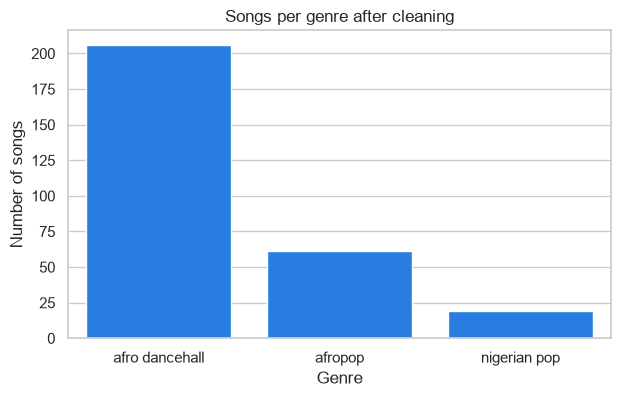

In [10]:
counts = df["artist_top_genre"].value_counts()

plt.figure(figsize=(7, 4))
sns.barplot(x=counts.index, y=counts.values, color="#0A7AFF")
plt.title("Songs per genre after cleaning")
plt.xlabel("Genre")
plt.ylabel("Number of songs")
plt.show()

The bar chart shows that the three genres are **very unequal**: 206 afro dancehall songs, 61 afropop and 19 nigerian pop. About **72%** of the songs are afro dancehall. Remember this: when one group is much bigger than the others, it is hard for any algorithm to find the small groups.

## 4. Explore the data

### Which features move together?

A **correlation** shows how strongly two features rise or fall together:

- **+1**: when one goes up, the other always goes up
- **0**: no straight-line relationship
- **−1**: when one goes up, the other always goes down

The heatmap shows the correlation for every pair of features. Red = positive, blue = negative, pale = close to 0.

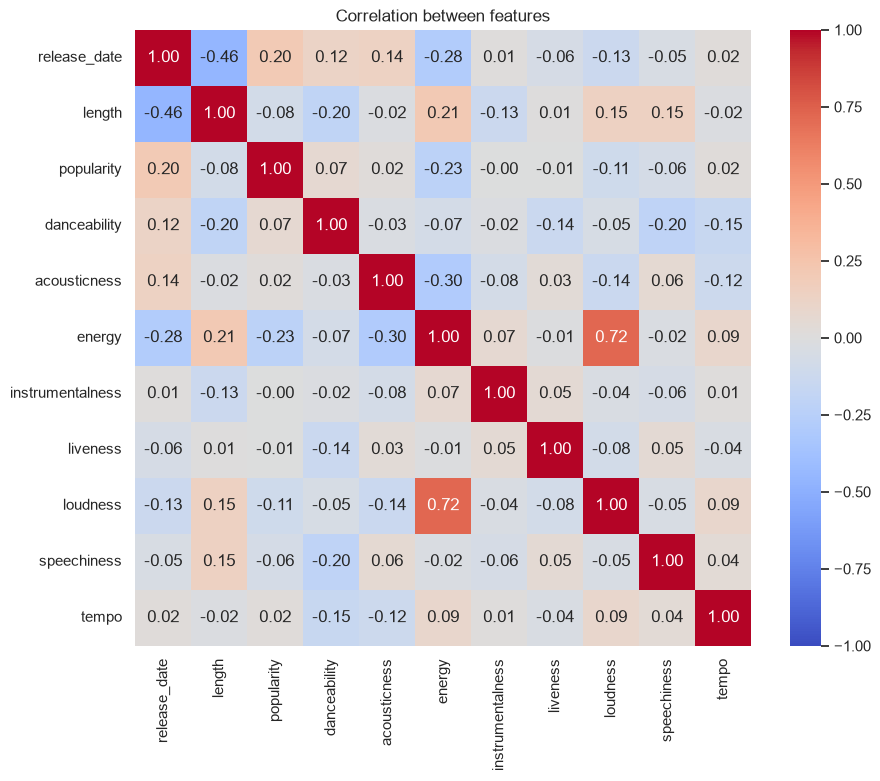

In [11]:
features = ["release_date", "length", "popularity", "danceability", "acousticness",
            "energy", "instrumentalness", "liveness", "loudness", "speechiness", "tempo"]

corr = df[features].corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation between features")
plt.show()

**What we see:**

- **energy and loudness: +0.72**, the strongest link. Louder songs feel more energetic, which makes sense.
- **length and release_date: −0.46**. Newer songs tend to be shorter.
- **popularity and release_date: +0.20**. Newer songs are slightly more popular.
- Most other pairs are close to 0: the features are mostly unrelated.

Note: correlation only catches **straight-line** relationships.

<span style="color:red;"><b>Question:</b> If two features are strongly correlated, does one cause the other?</span>

<span style="color:green;"><b>Answer:</b></span><br>
No. **Correlation is not causation.** A correlation only says that two features tend to go up or down together, not *why*.

- **energy and loudness (+0.72):** here the link is easy to explain, because Spotify partly uses loudness to calculate energy.
- **length and release_date (−0.46):** newer songs are shorter. Releasing a song doesn't make it shorter: something else is behind it. One common explanation is streaming: services pay per play, so shorter songs have become more common.

<span style="color:red;"><b>Question:</b> Why should we care about correlated features when clustering?</span>

<span style="color:green;"><b>Answer:</b></span><br>
Distances add up the differences across **all** features. If two features measure almost the same thing, like energy and loudness, that idea is counted **twice** and gets more weight than the other features.

That isn't always a problem, but it is worth knowing when you choose features. Sometimes it is better to keep only one of two strongly correlated features.

### Do the genres look different?

If the three genres are clearly separated in a plot, a clustering algorithm has a chance to find them. Let's look at popularity and danceability:

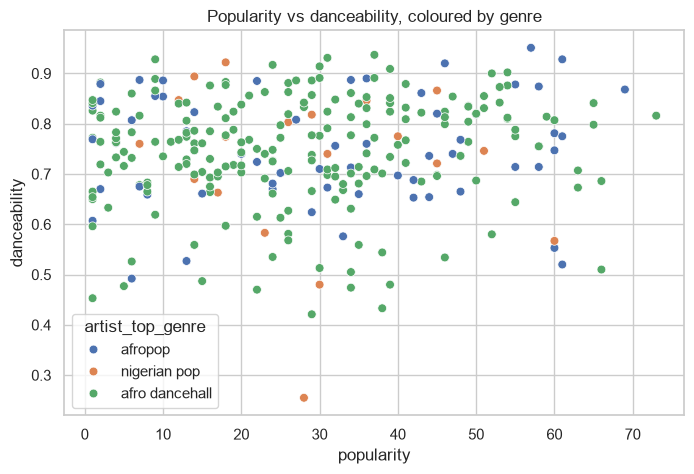

In [12]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="popularity", y="danceability", hue="artist_top_genre", s=40)
plt.title("Popularity vs danceability, coloured by genre")
plt.show()

**Kernel Density Estimation**

![kde.png](attachment:kde.png)

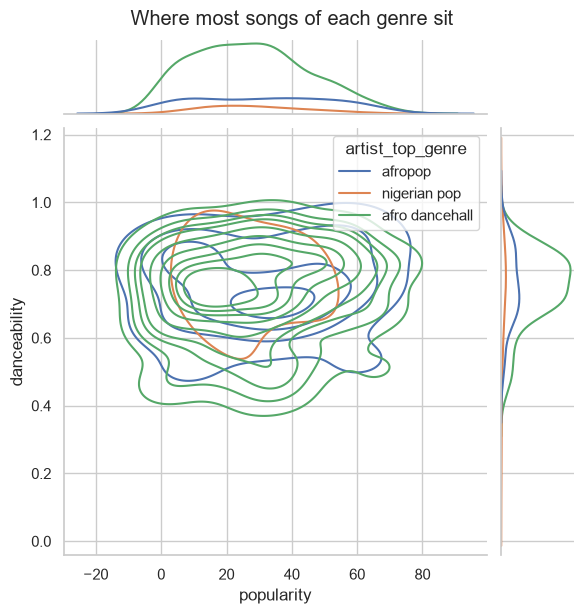

In [13]:
g = sns.jointplot(data=df, x="popularity", y="danceability", hue="artist_top_genre", kind="kde")
g.figure.suptitle("Where most songs of each genre sit", y=1.02)
plt.show()

**Key observation:** the three genres sit **on top of each other**. On these two features, the genres look very similar.

> Add blockquote



<span style="color:red;"><b>Question:</b> If the genres overlap this much, is clustering useless here?</span>

<span style="color:green;"><b>Answer:</b></span><br>
No. It only means that **these features** don't separate **these genres**. Clustering can still find **other** useful groups, for example "loud, energetic songs" or "calm, acoustic songs", that cut across the genres.

Genre is just **one** way to label songs, and it is decided by people. Clustering looks for groups in the **numbers**. When the two don't match, that tells us something true about the data: on these features, the three genres sound very similar. We test this properly next lesson.

## 5. Distance: how similar are two points?

In clustering, **similar = close**. To measure "close" we need a **distance**. We use the two points from the slides: **A = (2, 3)** and **B = (5, 7)**. To get from A to B we go 3 steps right and 4 steps up.

In [14]:
from scipy.spatial import distance

A = np.array([2, 3])
B = np.array([5, 7])

print("Euclidean (straight line):", distance.euclidean(A, B))          # sqrt(3² + 4²) = 5
print("Manhattan (along the grid):", distance.cityblock(A, B))         # 3 + 4 = 7
print("Cosine similarity (same direction?):", round(1 - distance.cosine(A, B), 4))

Euclidean (straight line): 5.0
Manhattan (along the grid): 7
Cosine similarity (same direction?): 0.9995


- **Euclidean = 5**: the straight line. This is what K-means uses.
- **Manhattan = 7**: walking along the grid, like city blocks.
- **Cosine ≈ 1**: A and B point in almost the same direction from (0, 0), so cosine says "very similar", even though they are 5 apart.

**Jaccard** works on *sets* (yes/no data), not on coordinates:

In [15]:
set1 = {"a", "b", "c"}
set2 = {"b", "c", "d"}

jaccard = len(set1 & set2) / len(set1 | set2)
print("Shared:", set1 & set2, " Total:", set1 | set2)
print("Jaccard similarity:", jaccard)      # 2 / 4 = 0.5

Shared: {'b', 'c'}  Total: {'c', 'd', 'b', 'a'}
Jaccard similarity: 0.5


<span style="color:red;"><b>Question:</b> Which distance should I use?</span>

<span style="color:green;"><b>Answer:</b></span><br>
It depends on your data:

- **Euclidean** (straight line): the default for numbers. K-means always uses it. Use it unless you have a reason not to.
- **Manhattan** (along the grid): differences are added, not squared, so one big difference in a single feature counts less. Useful when your data has outliers.
- **Cosine** (direction): compares the *pattern* of the numbers, not their size. Used for text, where a long and a short article about the same topic should count as similar.
- **Jaccard** (overlap of sets): for yes/no data, like the products in two shopping baskets.

For the songs we use **Euclidean**, after scaling the features.

<span style="color:red;"><b>Question:</b> Why does cosine say A and B are very similar, when Euclidean says they are 5 apart?</span>

<span style="color:green;"><b>Answer:</b></span><br>
They measure different things. Imagine an arrow from (0, 0) to each point.

- **Euclidean** measures how far apart the **tips** of the arrows are: 5.
- **Cosine** only looks at the **direction** of the arrows. A = (2, 3) and B = (5, 7) point almost the same way, so cosine similarity is about 1 (the maximum).

So B is like a "bigger version" of A. Cosine ignores the size and only asks whether the pattern is the same.

### Distance between two real songs

Now two real songs, using two features: popularity and danceability.

In [16]:
two = ["popularity", "danceability"]
song1 = df.iloc[0]
song2 = df.iloc[1]

print("Song 1:", song1["name"], "| popularity", song1["popularity"], "| danceability", song1["danceability"])
print("Song 2:", song2["name"], "| popularity", song2["popularity"], "| danceability", song2["danceability"])

diff = song1[two].astype(float) - song2[two].astype(float)
print()
print(pd.DataFrame({"difference": diff, "squared difference": diff ** 2}).round(3))
print("\nEuclidean distance:", round(float(np.sqrt((diff ** 2).sum())), 2))

Song 1: shuga rush | popularity 30 | danceability 0.71
Song 2: Confident / Feeling Cool | popularity 14 | danceability 0.894

              difference  squared difference
popularity        16.000             256.000
danceability      -0.184               0.034

Euclidean distance: 16.0


Look at the squared differences: **popularity contributes almost everything**, danceability almost nothing. That is not because danceability is unimportant, it is only because popularity is measured in bigger numbers (0–100 vs 0–1).

## 6. Why scaling matters

`StandardScaler` rescales every feature so it has **mean 0** and **spread (standard deviation) 1**. After scaling, a value tells you *how far above or below the average* a song is, measured in standard deviations. For example, a scaled popularity of +1.5 means "1.5 standard deviations more popular than the average song". Because every feature is now measured the same way, every feature counts equally in the distance.

In [17]:
from sklearn.preprocessing import StandardScaler

audio = ["popularity", "danceability", "acousticness", "loudness", "energy"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[audio])
scaled = pd.DataFrame(X_scaled, columns=audio, index=df.index)

print("Before scaling:")
print(df[audio].describe().loc[["mean", "std"]].round(2))
print("\nAfter scaling:")
print(scaled.describe().loc[["mean", "std"]].round(2))

Before scaling:
      popularity  danceability  acousticness  loudness  energy
mean       28.17          0.75          0.26     -4.92    0.76
std        17.73          0.11          0.20      2.40    0.14

After scaling:
      popularity  danceability  acousticness  loudness  energy
mean         0.0          -0.0          -0.0      -0.0     0.0
std          1.0           1.0           1.0       1.0     1.0


**How the code works:**

- `StandardScaler()` creates the scaler.
- `fit_transform(df[audio])` does two things: **fit** calculates the mean and standard deviation of each feature, and **transform** uses them to rescale every value: *(value − mean) ÷ standard deviation*.
- We wrap the result in a DataFrame called `scaled`, so it keeps the column names.

**Result:** before scaling, popularity has a standard deviation of about 18 while danceability has only 0.11. After scaling, every feature has mean **0** and standard deviation **1**.

In [18]:
diff_scaled = scaled.iloc[0][two] - scaled.iloc[1][two]
print(pd.DataFrame({"difference": diff_scaled, "squared difference": diff_scaled ** 2}).round(3))

              difference  squared difference
popularity         0.904               0.817
danceability      -1.642               2.697


Compare this with section 5: before scaling, popularity contributed

1.   List item
2.   List item

256 to the squared distance and danceability only 0.03. Now danceability contributes **more** than popularity (2.70 vs 0.82), because these two songs really differ more in danceability compared with how much songs usually vary.

<span style="color:red;"><b>Question:</b> Does scaling change the data or the shape of the plot?</span>

<span style="color:green;"><b>Answer:</b></span><br>
Scaling changes the **units**, not the **order** or the **pattern**. The most popular song is still the most popular one, and if you plot a scaled feature, the shape looks exactly the same: only the numbers on the axis change.

What changes is how much each feature counts in the **distance**. That's why the clusters change, even though the data points themselves keep their relative positions.

<span style="color:red;"><b>Question:</b> Should we scale the genre column too?</span>

<span style="color:green;"><b>Answer:</b></span><br>
No. The genre is **text** and the **label**: the answer we want to compare with later. It doesn't go into the clustering at all, so there is nothing to scale.

If you turned the genres into numbers (0, 1, 2) and put them into the clustering, you would be giving the model the answer, and the numbers would also suggest that genre 2 is "bigger" than genre 1, which makes no sense. We look at this trap next lesson.

Now both features matter. Let's see what that does to clustering. We use **K-means** with k = 3 (you'll learn exactly how it works next lesson):

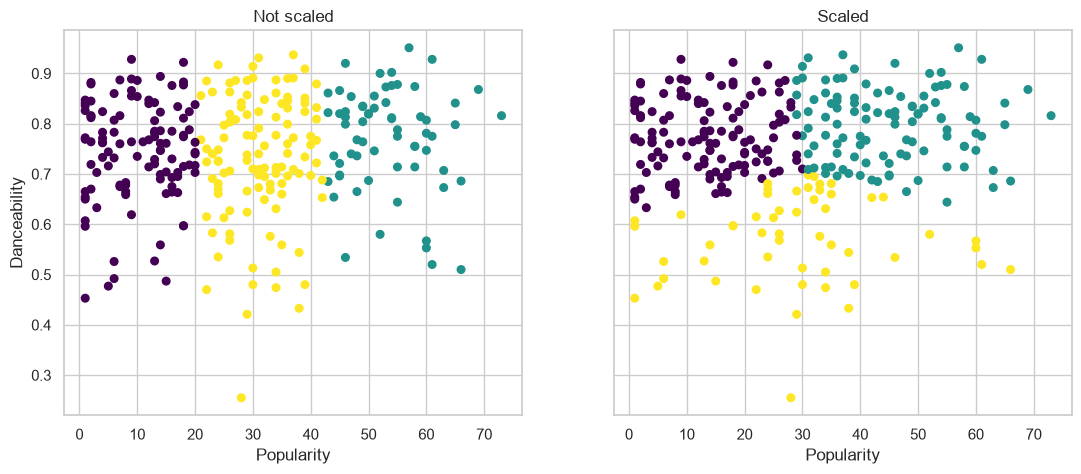

In [19]:
from sklearn.cluster import KMeans

raw_labels = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(df[two])
scaled_labels = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(scaled[two])

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, labels, title in [(axes[0], raw_labels, "Not scaled"), (axes[1], scaled_labels, "Scaled")]:
    ax.scatter(df["popularity"], df["danceability"], c=labels, cmap="viridis", s=30)
    ax.set_title(title)
    ax.set_xlabel("Popularity")
axes[0].set_ylabel("Danceability")
plt.show()

**Not scaled:** the clusters are just **vertical bands of popularity**. Danceability was ignored.<br>
**Scaled:** danceability counts too. The low-danceability songs get their own group.

<span style="color:red;"><b>Question:</b> Do I always need to scale before clustering?</span>

<span style="color:green;"><b>Answer:</b></span><br>
Almost always, whenever your features use **different units or ranges** (like popularity 0–100 and danceability 0–1). Without scaling, the feature with the biggest numbers decides everything.

The only time you can skip it is when all features are already in the same unit and range, for example the x and y coordinates on a map, or the colour values of pixels in an image.

`StandardScaler` is the most common choice. Another option is `MinMaxScaler`, which squeezes every feature into the range 0 to 1.

## 7. Hierarchical clustering

**How it works:**
1. Start: every point is its own cluster.
2. Merge the two closest clusters.
3. Repeat until everything is one cluster.

The merges form a tree called a **dendrogram**. Here are the five points **a–e** from the slides. We use `linkage` from SciPy to build the tree and `dendrogram` to draw it.

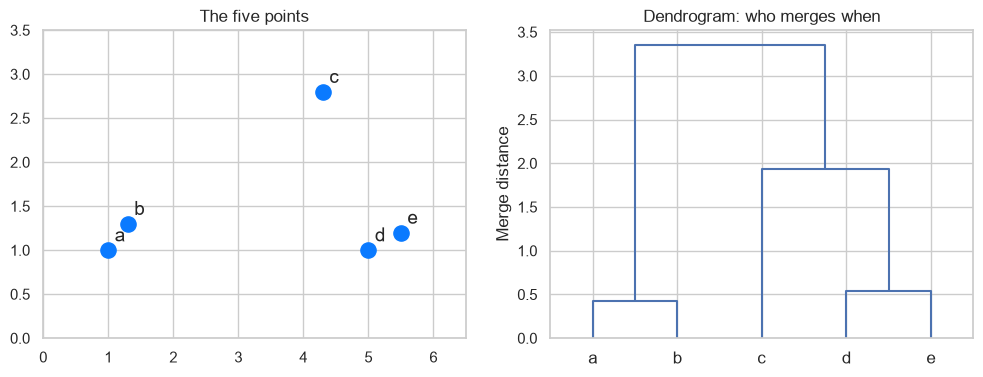

In [20]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

points = np.array([[1.0, 1.0], [1.3, 1.3], [4.3, 2.8], [5.0, 1.0], [5.5, 1.2]])
names = ["a", "b", "c", "d", "e"]

tree = linkage(points, method="single")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(points[:, 0], points[:, 1], s=120, color="#0A7AFF")
for (x, y), n in zip(points, names):
    axes[0].annotate(n, (x + 0.1, y + 0.1), fontsize=14)
axes[0].set_title("The five points")
axes[0].set_xlim(0, 6.5); axes[0].set_ylim(0, 3.5)

dendrogram(tree, labels=names, ax=axes[1], color_threshold=0)
axes[1].set_title("Dendrogram: who merges when")
axes[1].set_ylabel("Merge distance")
plt.show()

<span style="color:red;"><b>Question:</b> What do `method="single"` and `method="ward"` mean?</span>

<span style="color:green;"><b>Answer:</b></span><br>
They decide how the distance between two **clusters** is measured, which decides which clusters merge next:

- **single**: the distance between the two **closest** points of the clusters. Good for simple examples and for following long, chain-like shapes.
- **ward**: merge the two clusters that make the groups **least spread out**. This usually gives compact, round, similar-sized clusters, a bit like K-means. It is the default in scikit-learn.

For the five toy points both give the same tree; for the real songs we use `ward`.

**How to read the dendrogram:** the lower a joint, the earlier (and closer) the merge.

- **a + b** merge first (closest pair), then **d + e**, then **c** joins **de**, and finally everything joins.
- **You choose k afterwards:** draw a horizontal line across the tree. The number of vertical lines it cuts = the number of clusters. A line just below the top cuts 2 lines: {a, b} and {c, d, e}.

### A dendrogram of real songs

Now 30 randomly chosen songs, using the 5 scaled features from section 6. We use `method="ward"`, which merges the two clusters that keep the groups as tight as possible:

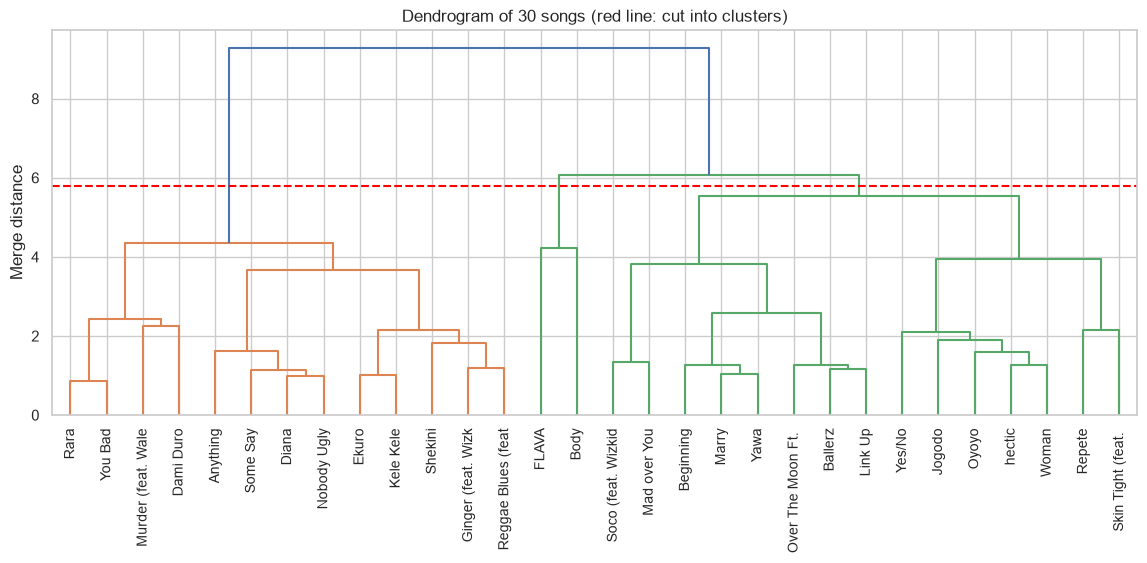

Number of clusters at this cut: 3


In [21]:
sample = scaled.sample(30, random_state=1)
sample_names = df.loc[sample.index, "name"].str.slice(0, 18)

song_tree = linkage(sample, method="ward")

plt.figure(figsize=(14, 5))
dendrogram(song_tree, labels=sample_names.values, leaf_rotation=90)
plt.axhline(y=5.8, color="red", linestyle="--")
plt.title("Dendrogram of 30 songs (red line: cut into clusters)")
plt.ylabel("Merge distance")
plt.show()

groups = fcluster(song_tree, t=5.8, criterion="distance")
print("Number of clusters at this cut:", len(set(groups)))

Move the red line up or down (change `y=5.8` and `t=5.8`) and the number of clusters changes. That is the big advantage of hierarchical clustering: **you can choose k after seeing the tree**.

In scikit-learn, the same idea is `AgglomerativeClustering`:

<span style="color:red;"><b>Question:</b> How do I decide where to cut the dendrogram?</span>

<span style="color:green;"><b>Answer:</b></span><br>
Look for a place where the vertical lines are **long**. A long line means the next merge joins two groups that are far apart, so it's a natural place to stop.

In the song dendrogram, the last merge happens at a height of about 9.3, but the merges below it are all under 6.1. Cutting anywhere between 6.1 and 9.3 gives 2 clusters; cutting at 5.8 gives 3.

You can also use what you know about the data: if you need 3 groups for a business reason, cut where you get 3. Next lesson we learn two more tools for choosing the number of clusters: the **elbow method** and the **silhouette score**.

In [22]:
from sklearn.cluster import AgglomerativeClustering

agg = AgglomerativeClustering(n_clusters=3, linkage="ward")
df["agg_cluster"] = agg.fit_predict(scaled)
df["agg_cluster"].value_counts()

agg_cluster
0    152
1    108
2     26
Name: count, dtype: int64

## 8. Which algorithm when?

Different algorithms suit different **shapes** of data. We compare **K-means** with **DBSCAN** (density-based) on two datasets:

- **Rings**: a curved shape
- **Random**: points with no real groups at all

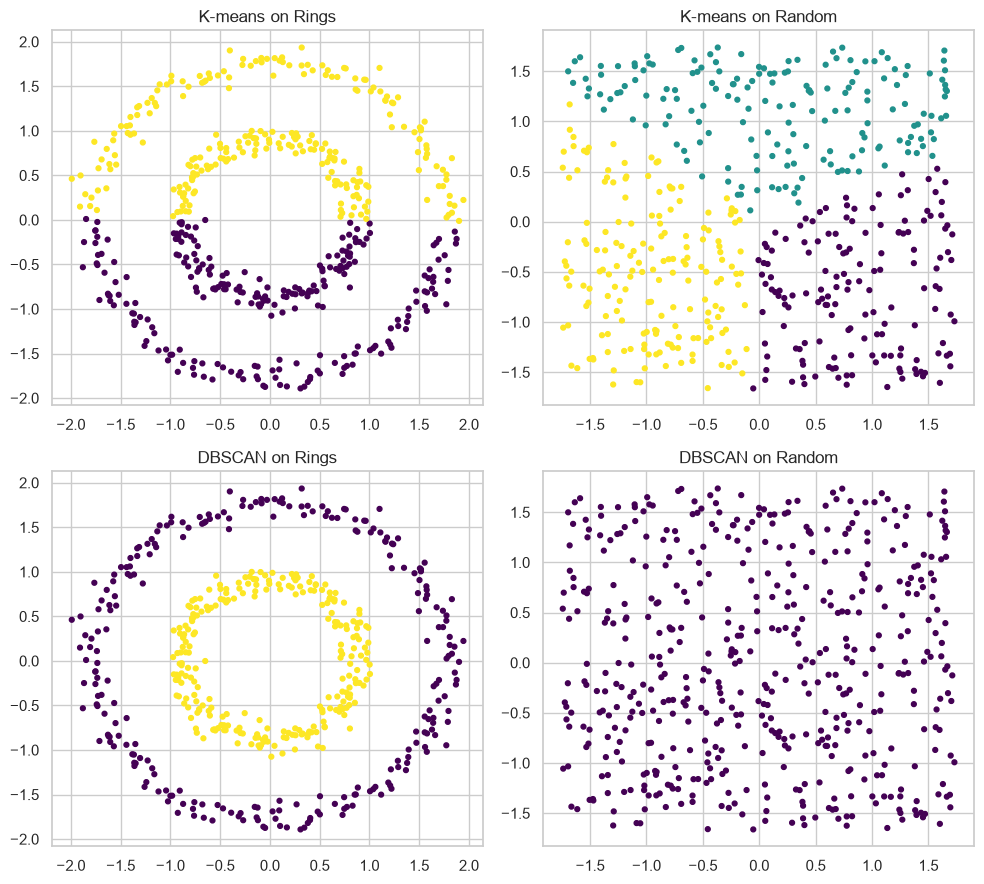

In [23]:
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_circles

rings, _ = make_circles(n_samples=500, factor=0.5, noise=0.05, random_state=0)
random_points = np.random.RandomState(0).rand(500, 2)

rings = StandardScaler().fit_transform(rings)
random_points = StandardScaler().fit_transform(random_points)

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for col, (data, k, name) in enumerate([(rings, 2, "Rings"), (random_points, 3, "Random")]):
    km_labels = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(data)
    db_labels = DBSCAN(eps=0.3).fit_predict(data)
    axes[0, col].scatter(data[:, 0], data[:, 1], c=km_labels, cmap="viridis", s=12)
    axes[0, col].set_title(f"K-means on {name}")
    axes[1, col].scatter(data[:, 0], data[:, 1], c=db_labels, cmap="viridis", s=12)
    axes[1, col].set_title(f"DBSCAN on {name}")
plt.tight_layout()
plt.show()

**Rings:** K-means cuts the rings in half (it only makes round groups). DBSCAN follows the curved shape.<br>
**Random:** there are **no real groups**, but K-means still finds 3 clusters. DBSCAN says "one group".<br>

**Clustering always gives an answer, so always check it.**

<span style="color:red;"><b>Question:</b> Why does DBSCAN call the random data one group, and what is `eps`?</span>

<span style="color:green;"><b>Answer:</b></span><br>
DBSCAN groups points that sit in **crowded** areas. `eps` is the size of the "neighbourhood" around each point: if a point has enough neighbours within distance `eps`, it is in a crowded area.

In the random data, the points are spread evenly, so every area is equally crowded. There are no empty gaps between groups, so DBSCAN finds just **one** big group. That is the honest answer: there are no real clusters.

`eps` matters a lot: if it is too small, DBSCAN breaks the data into many tiny groups and marks lots of points as noise; if it is too big, everything merges into one group.

<span style="color:red;"><b>Question:</b> So should I always use DBSCAN instead of K-means?</span>

<span style="color:green;"><b>Answer:</b></span><br>
No. Each algorithm has strengths:

- **K-means** is fast, simple and works very well when the groups are roughly **round** and similar in size. It can also sort **new** data points into the clusters it learned.
- **DBSCAN** handles **curved shapes** and **noise**, and doesn't need k. But you have to choose `eps`, it struggles when groups have very different densities, and it can't sort new points.

The best choice depends on the shape of your data, which is why we always look at the data first.

## 9. *(Optional)* Hard vs soft clustering

- **Hard clustering** (K-means, DBSCAN, hierarchical): each point belongs to **exactly one** cluster.
- **Soft clustering** (Gaussian mixture): each point gets a **share** of every cluster.

Hard label (K-means style): [1]
Soft shares (cluster 0, cluster 1): [[0.42 0.58]]


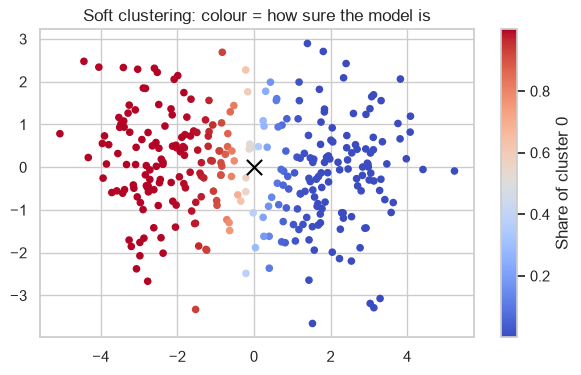

In [24]:
from sklearn.datasets import make_blobs
from sklearn.mixture import GaussianMixture

blobs, _ = make_blobs(n_samples=300, centers=[(-2, 0), (2, 0)], cluster_std=1.2, random_state=0)
gmm = GaussianMixture(n_components=2, random_state=0).fit(blobs)

border_point = np.array([[0.0, 0.0]])
print("Hard label (K-means style):", gmm.predict(border_point))
print("Soft shares (cluster 0, cluster 1):", gmm.predict_proba(border_point).round(2))

share = gmm.predict_proba(blobs)[:, 0]
plt.figure(figsize=(7, 4))
plt.scatter(blobs[:, 0], blobs[:, 1], c=share, cmap="coolwarm", s=20)
plt.colorbar(label="Share of cluster 0")
plt.scatter(0, 0, color="black", s=120, marker="x")
plt.title("Soft clustering: colour = how sure the model is")
plt.show()

Points in the middle are pale (close to 50/50): the model is **not sure**. The black × at (0, 0) is 42% / 58%. A hard clustering would force them into one side.

<span style="color:red;"><b>Question:</b> When is soft clustering better than hard clustering?</span>

<span style="color:green;"><b>Answer:</b></span><br>
When the groups **overlap**, and the points in between really do belong partly to both. For example:

- **Customers:** someone who buys both baby products and gaming gear can be 50% "parent" and 50% "gamer".
- **Songs:** a song can be partly "dance track" and partly "calm ballad".

Soft clustering also tells you **how sure** the model is about each point. Points with shares close to 50/50 are the uncertain border cases. A hard clustering hides that uncertainty by forcing every point into one cluster.

## 10. Recap

**What we did:**

| Section | What we learned |
|---|---|
| 2. Inspect | `info()` and `describe()` show the types and ranges. Missing data can hide as text ("Missing") or as numbers (popularity 0). |
| 3. Clean | We removed songs with no genre, rare genres and popularity 0, from 530 down to **286 songs**. Every cleaning step needs a reason. |
| 4. Explore | Energy and loudness are strongly related (+0.72). The three genres **overlap** heavily on popularity and danceability. |
| 5. Distance | Similar = close. Euclidean (5) and Manhattan (7) measure size; cosine measures direction; Jaccard compares sets. |
| 6. Scaling | Without scaling, big-number features like popularity dominate the distance. `StandardScaler` makes every feature count equally. |
| 7. Hierarchical | Merge the closest clusters step by step. The dendrogram lets you **choose k afterwards**. |
| 8. Which algorithm | K-means likes round groups; DBSCAN handles curves and noise. K-means found 3 clusters in random data, so **always check the result**. |
| 9. Soft clustering | A point can belong partly to several clusters, which shows how sure the model is. |

**Key takeaways:**

- **Clustering** finds groups in data **without labels**.
- **Look for hidden missing values** before you trust the data.
- **Similar = close**: the distance measure decides what "similar" means.
- **Scale your features first**, or big-number features decide everything.
- **The shape of the data matters** when you choose an algorithm.
- **Clustering always returns groups**, even when there are none, so always look at the result.

**Next lesson: K-Means Clustering.** We learn exactly how K-means works, how to choose k with the **elbow method** and the **silhouette score**, and we answer the big question: **can K-means find the three genres in the Nigerian songs?**